### Load Packages

In [1]:
import numpy as np 
import pandas as pd
import matplotlib.pyplot as plt
import os
import math
import matplotlib.colors as mcolors
import matplotlib.tri as tri
import torch
import gpytorch
from pyproj import Proj, transform
from matplotlib import rcParams as rc
import matplotlib
from mpl_toolkits.mplot3d import Axes3D
from sklearn.preprocessing import StandardScaler
from pickle import dump, load
import linear_operator
import random
from shapely.geometry import Polygon
import geopandas as gpd

#import user models
#from pylib_gp_twoscale import VelGPModel, Genevarikernel
from pylib_gp_twoscale import VelGPModel, Genevarikernel

configs = {
    'xtick.direction': 'in',
    'ytick.direction': 'in',
    'font.sans-serif': ['Times New Roman'],
     #'font.sans-serif': ['Microsoft YaHei', 'SimHei', 'Arial', 'Liberation Sans', 'sans-serif'],
    #'font.sans-serif': ['Palatino Linotype', 'Microsoft YaHei', 'SimHei', 'Arial', 'Liberation Sans', 'sans-serif'],
    'axes.grid': True,
    'grid.alpha': 0.5,
    'grid.linestyle': '--',
    'mathtext.fontset': "cm",
    # 'mathtext.rm': "asana math",
    # 'mathtext.cal': "asana math",
    "font.size": 16,
    # 'axes.labelsize': 'large',
    # 'axes.labelpad': 8.0,
    # 'xtick.major.pad': 9.0,
}
rc.update(configs)

In [2]:
norm = mcolors.Normalize(vmin=150., vmax=2000.)  
cmap = matplotlib.colormaps.get_cmap("coolwarm")
red_color = cmap(0.9)
blue_color = cmap(0.1)
gray_color = cmap(0.5)

color_maps = {
    "input": gray_color,
    "Expected": red_color,
    "Predicted": blue_color,
}

### Define Variables

In [3]:
#define corss-section
name_crssect = 'Cross Section ' + str(id)
fname_crssect = name_crssect.lower().replace(' ','_')

#cross-section extents
crssect_depth = [0, 500]

#descritization
crssect_npt_xy = 100
crssect_npt_z  = 20
crs_grid = []

#model directory
dir_model = './'

#model column names (input, output)
cn_x = ['vs_depth','Z_2.5','surf_elevation','easting','northing'] #output
cn_y = 'diff'                                                     #input

#define output directories
dir_out = '../Data/Vel_data/'
dir_fig = '../Data/Figure/'

### Load Training Data (Vs Measurements)

In [4]:
#read the entire data
df_measure = pd.read_csv(dir_out+'Training_data/df_measure.txt', encoding='utf-8')
df_measure = df_measure.rename(columns={'metadata_id': 'velocity_metadata_id', 'z_2.5': 'Z_2.5',
                                       'vs_middle_depth': 'vs_depth'})
df_measure

,velocity_metadata_id,vs_depth,vs_value,vs_top_depth,vs_bottom_depth,test_id,velocity_name,velocity_method,velocity_date,velocity_quality,...,terrain_class,site_easting,site_northing,test_easting,test_northing,vs_model,surf_elevation,Z_2.5,diff,basin_idnum
0,610,1.00,155.0,0.5,1.5,542,ELC,Suspension Logging,1996-09-26,NaN,...,4,352134.046903,3.786794e+06,352134.046903,3.786794e+06,938.187,251.052,2380.0,-1.800524,2
1,610,2.00,170.2,1.5,2.5,542,ELC,Suspension Logging,1996-09-26,NaN,...,4,352134.046903,3.786794e+06,352134.046903,3.786794e+06,939.068,251.052,2380.0,-1.707914,2
2,610,3.00,196.5,2.5,3.5,542,ELC,Suspension Logging,1996-09-26,NaN,...,4,352134.046903,3.786794e+06,352134.046903,3.786794e+06,939.949,251.052,2380.0,-1.565163,2
3,610,4.00,191.9,3.5,4.5,542,ELC,Suspension Logging,1996-09-26,NaN,...,4,352134.046903,3.786794e+06,352134.046903,3.786794e+06,940.830,251.052,2380.0,-1.589788,2
4,610,5.00,202.0,4.5,5.5,542,ELC,Suspension Logging,1996-09-26,NaN,...,4,352134.046903,3.786794e+06,352134.046903,3.786794e+06,941.711,251.052,2380.0,-1.539431,2
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
11026,2479,12.60,354.0,9.3,15.9,2419,VS,MASW,NaN,NaN,...,8,400420.745906,3.762835e+06,400420.745906,3.762835e+06,894.882,54.938,3620.0,-0.927395,1
11027,2479,21.15,387.0,15.9,26.4,2419,VS,MASW,NaN,NaN,...,8,400420.745906,3.762835e+06,400420.745906,3.762835e+06,899.010,54.938,3620.0,-0.842869,1
11028,2479,34.80,445.0,26.4,43.2,2419,VS,MASW,NaN,NaN,...,8,400420.745906,3.762835e+06,400420.745906,3.762835e+06,905.600,54.938,3620.0,-0.710523,1
11029,2479,56.60,540.0,43.2,70.0,2419,VS,MASW,NaN,NaN,...,8,400420.745906,3.762835e+06,400420.745906,3.762835e+06,916.125,54.938,3620.0,-0.528584,1


In [5]:
df_measure = df_measure[['vs_depth','Z_2.5','surf_elevation','site_easting','site_northing','diff',  'velocity_metadata_id','vs30','basin_idnum','vs_model','vs_value']]
df_measure = df_measure.rename(columns={'site_easting': 'easting', 'site_northing': 'northing'})
df_measure

,vs_depth,Z_2.5,surf_elevation,easting,northing,diff,velocity_metadata_id,vs30,basin_idnum,vs_model,vs_value
0,1.00,2380.0,251.052,352134.046903,3.786794e+06,-1.800524,610,295.692,2,938.187,155.0
1,2.00,2380.0,251.052,352134.046903,3.786794e+06,-1.707914,610,295.692,2,939.068,170.2
2,3.00,2380.0,251.052,352134.046903,3.786794e+06,-1.565163,610,295.692,2,939.949,196.5
3,4.00,2380.0,251.052,352134.046903,3.786794e+06,-1.589788,610,295.692,2,940.830,191.9
4,5.00,2380.0,251.052,352134.046903,3.786794e+06,-1.539431,610,295.692,2,941.711,202.0
...,...,...,...,...,...,...,...,...,...,...,...
11026,12.60,3620.0,54.938,400420.745906,3.762835e+06,-0.927395,2479,304.365,1,894.882,354.0
11027,21.15,3620.0,54.938,400420.745906,3.762835e+06,-0.842869,2479,304.365,1,899.010,387.0
11028,34.80,3620.0,54.938,400420.745906,3.762835e+06,-0.710523,2479,304.365,1,905.600,445.0
11029,56.60,3620.0,54.938,400420.745906,3.762835e+06,-0.528584,2479,304.365,1,916.125,540.0


In [6]:
df_sonic = pd.read_csv(dir_out+'Training_data/df_sonic.txt', encoding='utf-8')
df_sonic = df_sonic.rename(columns={'X': 'easting', 'Y': 'northing',
                                       'depth': 'vs_depth'})
df_sonic = df_sonic[['vs_depth','Z_2.5','surf_elevation','easting','northing','diff',  'velocity_metadata_id']]

df_sonic['basin_idnum'] = 1
df_sonic

,vs_depth,Z_2.5,surf_elevation,easting,northing,diff,velocity_metadata_id,basin_idnum
0,67.124000,4400.0,23.596,387402.0000,3753149.500,0.010634,-29,1
1,77.124000,4400.0,23.596,387402.0000,3753149.500,0.018006,-29,1
2,87.124000,4400.0,23.596,387402.0000,3753149.500,0.028627,-29,1
3,97.124000,4400.0,23.596,387402.0000,3753149.500,0.040313,-29,1
4,107.124000,4400.0,23.596,387402.0000,3753149.500,0.051009,-29,1
...,...,...,...,...,...,...,...,...
3177,1956.730197,2500.0,83.353,387298.0938,3767711.984,-0.116894,-28,1
3178,1966.730197,2500.0,83.353,387298.0938,3767711.984,-0.056673,-28,1
3179,1976.730197,2500.0,83.353,387298.0938,3767711.984,-0.040450,-28,1
3180,1986.730197,2500.0,83.353,387298.0938,3767711.984,-0.050204,-28,1


In [7]:
df_veldata = pd.concat([df_measure.reset_index(drop=True), df_sonic.reset_index(drop=True)], ignore_index=True, sort=False)
df_veldata

,vs_depth,Z_2.5,surf_elevation,easting,northing,diff,velocity_metadata_id,vs30,basin_idnum,vs_model,vs_value
0,1.000000,2380.0,251.052,352134.046903,3.786794e+06,-1.800524,610,295.692,2,938.187,155.0
1,2.000000,2380.0,251.052,352134.046903,3.786794e+06,-1.707914,610,295.692,2,939.068,170.2
2,3.000000,2380.0,251.052,352134.046903,3.786794e+06,-1.565163,610,295.692,2,939.949,196.5
3,4.000000,2380.0,251.052,352134.046903,3.786794e+06,-1.589788,610,295.692,2,940.830,191.9
4,5.000000,2380.0,251.052,352134.046903,3.786794e+06,-1.539431,610,295.692,2,941.711,202.0
...,...,...,...,...,...,...,...,...,...,...,...
14208,1956.730197,2500.0,83.353,387298.093800,3.767712e+06,-0.116894,-28,NaN,1,NaN,NaN
14209,1966.730197,2500.0,83.353,387298.093800,3.767712e+06,-0.056673,-28,NaN,1,NaN,NaN
14210,1976.730197,2500.0,83.353,387298.093800,3.767712e+06,-0.040450,-28,NaN,1,NaN,NaN
14211,1986.730197,2500.0,83.353,387298.093800,3.767712e+06,-0.050204,-28,NaN,1,NaN,NaN


### Load and Define GP Model

In [8]:
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

#read model
scaler_input = load(open(dir_model+'ucvm_la_basin_adj_scaler_frozen.pkl', 'rb'))
model_state = torch.load(dir_model+'ucvm_la_basin_adj_model_frozen_newloss.pth', weights_only=True)

#get training input/output
X_train = scaler_input.transform(df_veldata.loc[:,cn_x].values)
Y_train = df_veldata.loc[:,cn_y].values
#convert to tensors
X_train = torch.tensor(X_train, dtype=torch.float32)
Y_train = torch.tensor(Y_train, dtype=torch.float32)

basin_col = torch.tensor(
    df_veldata['basin_idnum'].to_numpy(),
    dtype=X_train.dtype,
    device=X_train.device
).unsqueeze(1)

X_train = torch.cat([X_train, basin_col], dim=1)
print(X_train)

#define likelihood and model
likelihood = gpytorch.likelihoods.GaussianLikelihood().to(device).double()
model = VelGPModel(X_train, Y_train, likelihood).to(device).double()
model.load_state_dict(model_state)

tensor([[-0.8257, -0.1854,  0.2379, -1.0547,  0.5051,  2.0000],
        [-0.8097, -0.1854,  0.2379, -1.0547,  0.5051,  2.0000],
        [-0.7936, -0.1854,  0.2379, -1.0547,  0.5051,  2.0000],
        ...,
        [30.8894, -0.1001, -0.6438,  0.1647, -0.1566,  1.0000],
        [31.0499, -0.1001, -0.6438,  0.1647, -0.1566,  1.0000],
        [31.2105, -0.1001, -0.6438,  0.1647, -0.1566,  1.0000]])


<All keys matched successfully>

In [9]:
X_train_cross = torch.tensor(scaler_input.transform(df_measure.loc[:,cn_x].values), dtype=torch.float32)


basin_col = torch.tensor(
    df_measure['basin_idnum'].to_numpy(),
    dtype=X_train_cross.dtype,
    device=X_train_cross.device
).unsqueeze(1)

X_train_cross = torch.cat([X_train_cross, basin_col], dim=1)
print(X_train_cross)


X_train_cross.max(axis=0)
X_train.max(axis=0)


df_veldata.loc[:,cn_x].values.max(axis=0)
df_veldata.loc[df_veldata.vs_depth > 380,:].velocity_metadata_id.unique()

tensor([[-0.8257, -0.1854,  0.2379, -1.0547,  0.5051,  2.0000],
        [-0.8097, -0.1854,  0.2379, -1.0547,  0.5051,  2.0000],
        [-0.7936, -0.1854,  0.2379, -1.0547,  0.5051,  2.0000],
        ...,
        [-0.2832,  0.6963, -0.7933,  0.6197, -0.3257,  1.0000],
        [ 0.0668,  0.6963, -0.7933,  0.6197, -0.3257,  1.0000],
        [ 0.3621,  0.6963, -0.7933,  0.6197, -0.3257,  1.0000]])


array([-29, -30, -31, -32, -33,  -1,  -2,  -3,  -4,  -5,  -6,  -7,  -8,
        -9, -10, -11, -12, -13, -14, -15, -16, -17, -18, -19, -22, -23,
       -24, -25, -26, -27, -28])

In [10]:
model.eval()
likelihood.eval()


X_pred = X_train_cross.to(device=device)

batch_size = 512   

pred_mean_list = []

with torch.no_grad(), gpytorch.settings.fast_pred_var(), gpytorch.settings.skip_posterior_variances(True):
    for i in range(0, X_pred.shape[0], batch_size):
        X_batch = X_pred[i:i + batch_size]

        pred = likelihood(model(X_batch))         
        pred_mean_list.append(pred.mean.detach().cpu())

predict_value = torch.cat(pred_mean_list, dim=0)

In [11]:
df_measure['predict_diff'] = predict_value
df_measure['predict_vs'] = df_measure["vs_model"].to_numpy() * np.exp(df_measure["predict_diff"].to_numpy())
df_measure['residual'] = np.log(df_measure['vs_value']) - np.log(df_measure['predict_vs'])
df_measure

,vs_depth,Z_2.5,surf_elevation,easting,northing,diff,velocity_metadata_id,vs30,basin_idnum,vs_model,vs_value,predict_diff,predict_vs,residual
0,1.00,2380.0,251.052,352134.046903,3.786794e+06,-1.800524,610,295.692,2,938.187,155.0,-1.738185,164.970127,-0.062339
1,2.00,2380.0,251.052,352134.046903,3.786794e+06,-1.707914,610,295.692,2,939.068,170.2,-1.664825,177.694041,-0.043089
2,3.00,2380.0,251.052,352134.046903,3.786794e+06,-1.565163,610,295.692,2,939.949,196.5,-1.565139,196.504723,-0.000024
3,4.00,2380.0,251.052,352134.046903,3.786794e+06,-1.589788,610,295.692,2,940.830,191.9,-1.555354,198.622981,-0.034434
4,5.00,2380.0,251.052,352134.046903,3.786794e+06,-1.539431,610,295.692,2,941.711,202.0,-1.505130,209.049014,-0.034301
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
11026,12.60,3620.0,54.938,400420.745906,3.762835e+06,-0.927395,2479,304.365,1,894.882,354.0,-0.997498,330.033490,0.070103
11027,21.15,3620.0,54.938,400420.745906,3.762835e+06,-0.842869,2479,304.365,1,899.010,387.0,-0.847331,385.277219,0.004462
11028,34.80,3620.0,54.938,400420.745906,3.762835e+06,-0.710523,2479,304.365,1,905.600,445.0,-0.689958,454.246142,-0.020565
11029,56.60,3620.0,54.938,400420.745906,3.762835e+06,-0.528584,2479,304.365,1,916.125,540.0,-0.518395,545.530104,-0.010189


In [12]:
dir_out = '../Data/Vel_data/Residual/'
df_measure.to_csv(dir_out+'vs_measure.txt', index=False,
                  encoding='utf-8',
                  lineterminator='\n')

findfont: Generic family 'sans-serif' not found because none of the following families were found: Times New Roman
findfont: Generic family 'sans-serif' not found because none of the following families were found: Times New Roman
findfont: Generic family 'sans-serif' not found because none of the following families were found: Times New Roman
findfont: Generic family 'sans-serif' not found because none of the following families were found: Times New Roman
findfont: Font family ['sans-serif'] not found. Falling back to DejaVu Sans.
findfont: Generic family 'sans-serif' not found because none of the following families were found: Times New Roman
findfont: Generic family 'sans-serif' not found because none of the following families were found: Times New Roman
findfont: Generic family 'sans-serif' not found because none of the following families were found: Times New Roman
findfont: Generic family 'sans-serif' not found because none of the following families were found: Times New Roman
fin

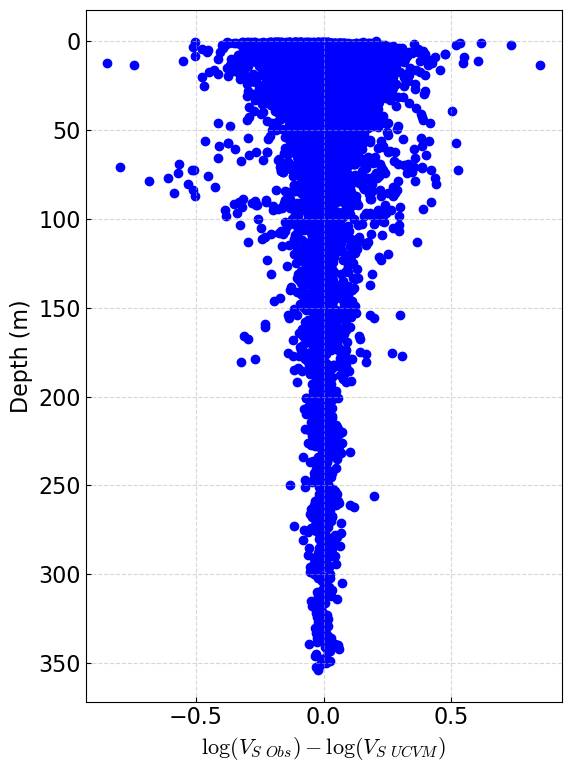

In [13]:
plt.figure(figsize=(6, 8))
plt.scatter(df_measure['residual'], df_measure['vs_depth'], color='blue')
plt.gca().invert_yaxis()
plt.xlabel(r'$\log(V_{S~Obs}) - \log(V_{S~UCVM})$')
plt.ylabel('Depth (m)')
# plt.legend()
plt.grid(True)
plt.tight_layout()
#plt.savefig(dir_fig+'vs_data_cleaned.svg', format='svg', dpi=300)
#plt.savefig(dir_fig+'vs_data_cleaned.png', format='png', dpi=300)
plt.show()

findfont: Font family 'Arial' not found.
findfont: Font family 'Arial' not found.
findfont: Font family 'Arial' not found.
findfont: Font family 'Arial' not found.
findfont: Font family 'Arial' not found.
findfont: Font family 'Arial' not found.
findfont: Font family 'Arial' not found.
findfont: Font family ['Arial'] not found. Falling back to DejaVu Sans.
findfont: Font family 'Arial' not found.
findfont: Font family 'Arial' not found.
findfont: Font family 'Arial' not found.
findfont: Font family 'Arial' not found.
findfont: Font family 'Arial' not found.
findfont: Font family 'Arial' not found.
findfont: Font family 'Arial' not found.
findfont: Font family 'Arial' not found.
findfont: Font family 'Arial' not found.
findfont: Font family 'Arial' not found.
findfont: Font family 'Arial' not found.
findfont: Font family 'Arial' not found.
findfont: Font family 'Arial' not found.
findfont: Font family 'Arial' not found.
findfont: Font family 'Arial' not found.
findfont: Font family ['Ar

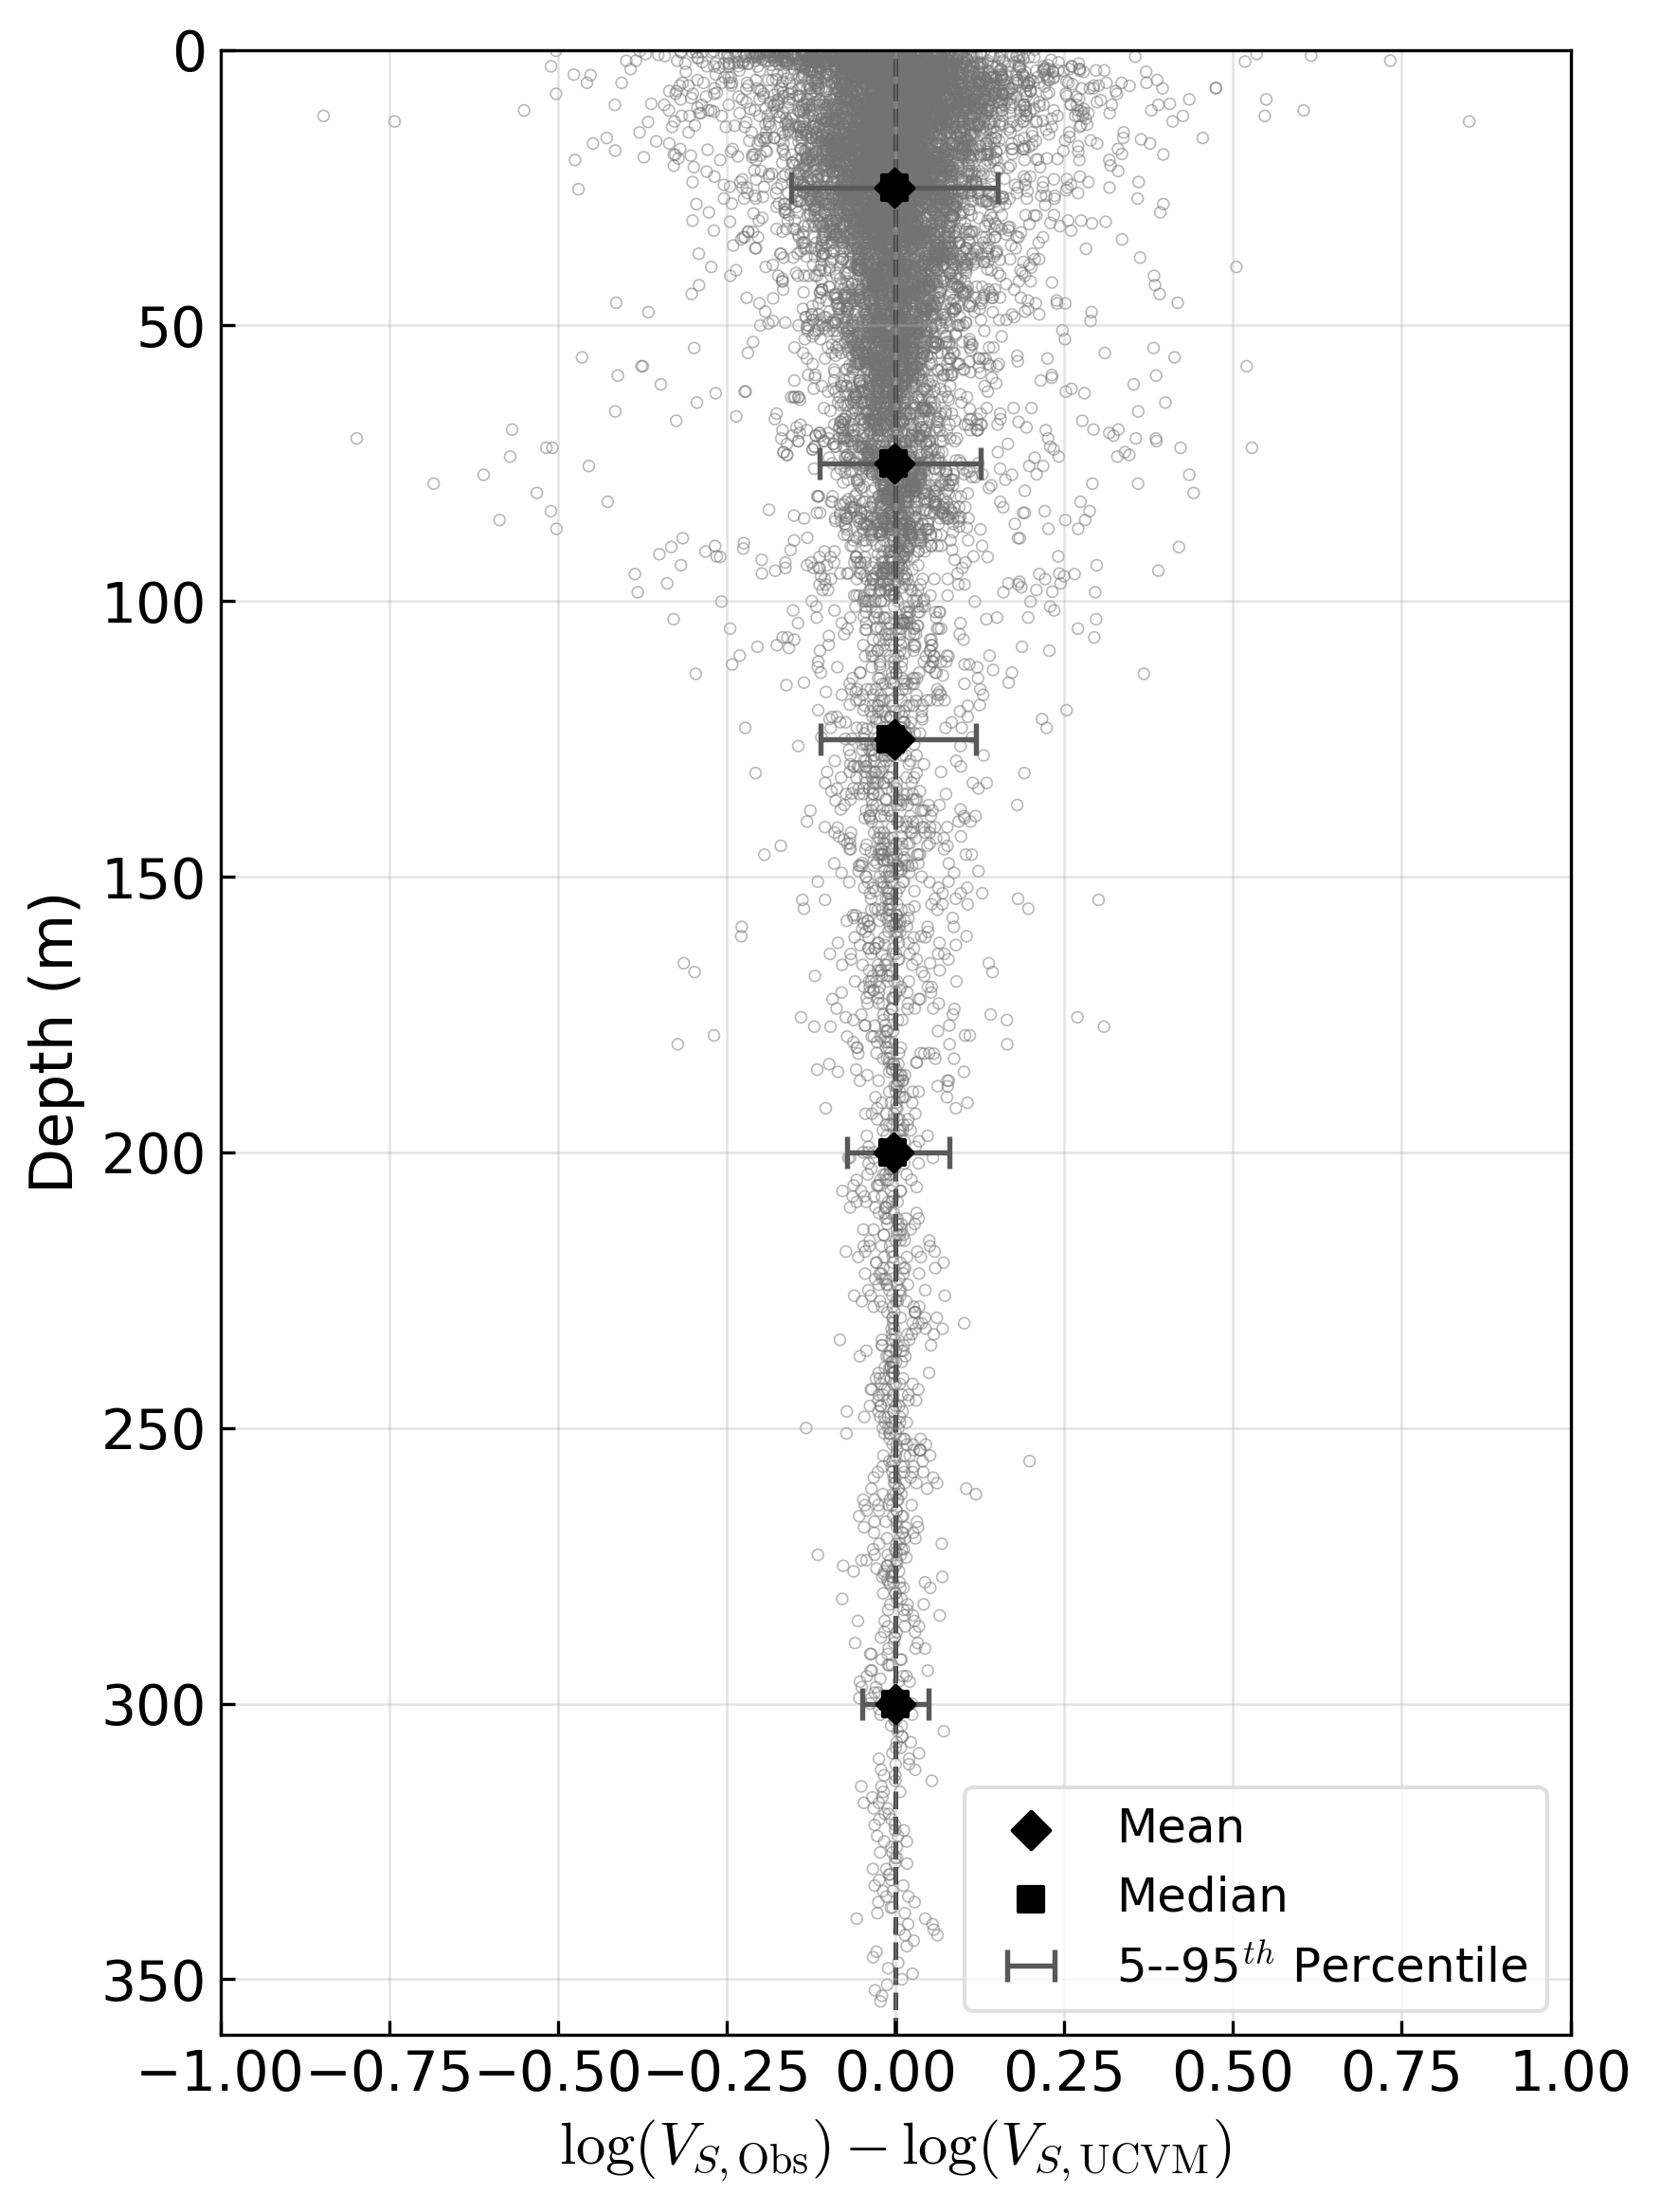

In [14]:
x = df_measure["residual"].to_numpy()
z = df_measure["vs_depth"].to_numpy()

mask = np.isfinite(x) & np.isfinite(z)
x = x[mask]
z = z[mask]

depth_bins = np.array([0, 50, 100, 150, 250, 350, 500])
depth_centers = 0.5 * (depth_bins[:-1] + depth_bins[1:])

stats = []

for zmin, zmax, zc in zip(depth_bins[:-1], depth_bins[1:], depth_centers):
    idx = (z >= zmin) & (z < zmax)
    x_bin = x[idx]

    if len(x_bin) > 0:
        stats.append([
            zc,
            np.mean(x_bin),
            np.median(x_bin),
            np.percentile(x_bin, 5),
            np.percentile(x_bin, 95),
            len(x_bin)
        ])

stats = pd.DataFrame(
    stats,
    columns=["depth", "mean", "median", "p16", "p84", "n"]
)


plt.rcParams["font.family"] = "Arial"
plt.rcParams["font.size"] = 14

fig, ax = plt.subplots(figsize=(6, 8), dpi=300)

ax.scatter(
    x, z,
    s=8,
    facecolors="none",
    edgecolors="0.45",
    linewidths=0.4,
    alpha=0.5,
    label="_nolegend_"
)

ax.axvline(
    0,
    color="0.25",
    linestyle="--",
    linewidth=1.2,
    zorder=1
)

ax.scatter(
    stats["mean"],
    stats["depth"],
    marker="D",
    s=45,
    color="black",
    label="Mean",
    zorder=5
)

ax.scatter(
    stats["median"],
    stats["depth"],
    marker="s",
    s=40,
    color="black",
    label="Median",
    zorder=5
)

xerr_lower = stats["median"] - stats["p16"]
xerr_upper = stats["p84"] - stats["median"]

ax.errorbar(
    stats["median"],
    stats["depth"],
    xerr=[xerr_lower, xerr_upper],
    fmt="none",
    ecolor="0.35",
    elinewidth=1.3,
    capsize=4,
    capthick=1.3,
    label=r"5--95$^{th}$ Percentile",
    zorder=4
)

ax.invert_yaxis()
ax.set_xlabel(r"$\log(V_{S,\mathrm{Obs}}) - \log(V_{S,\mathrm{UCVM}})$", fontsize=15)
ax.set_ylabel("Depth (m)", fontsize=15)
ax.set_xlim(-1, 1)
ax.set_ylim(360, 0)

ax.grid(
    True,
    linestyle="-",
    linewidth=0.6,
    alpha=0.35
)

ax.legend(
    loc="lower right",
    fontsize=12,
    frameon=True,
    edgecolor="0.85"
)

plt.tight_layout()
plt.show()

findfont: Font family 'Arial' not found.
findfont: Font family 'Arial' not found.
findfont: Font family 'Arial' not found.
findfont: Font family 'Arial' not found.
findfont: Font family 'Arial' not found.
findfont: Font family 'Arial' not found.
findfont: Font family 'Arial' not found.
findfont: Font family 'Arial' not found.
findfont: Font family ['Arial'] not found. Falling back to DejaVu Sans.
findfont: Font family 'Arial' not found.
findfont: Font family 'Arial' not found.
findfont: Font family 'Arial' not found.
findfont: Font family 'Arial' not found.
findfont: Font family 'Arial' not found.
findfont: Font family 'Arial' not found.
findfont: Font family 'Arial' not found.
findfont: Font family 'Arial' not found.
findfont: Font family 'Arial' not found.
findfont: Font family 'Arial' not found.
findfont: Font family 'Arial' not found.
findfont: Font family 'Arial' not found.
findfont: Font family 'Arial' not found.
findfont: Font family 'Arial' not found.
findfont: Font family 'Ari

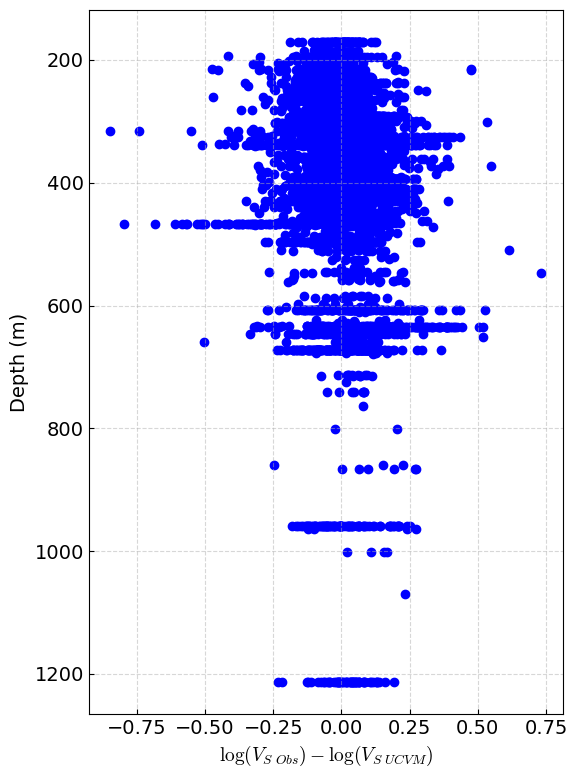

In [15]:
plt.figure(figsize=(6, 8))
plt.scatter(df_measure['residual'], df_measure['vs30'], color='blue')
plt.gca().invert_yaxis()
plt.xlabel(r'$\log(V_{S~Obs}) - \log(V_{S~UCVM})$')
plt.ylabel('Depth (m)')
# plt.legend()
plt.grid(True)
plt.tight_layout()
#plt.savefig(dir_fig+'vs_data_cleaned.svg', format='svg', dpi=300)
#plt.savefig(dir_fig+'vs_data_cleaned.png', format='png', dpi=300)
plt.show()

findfont: Font family 'Arial' not found.
findfont: Font family 'Arial' not found.
findfont: Font family 'Arial' not found.
findfont: Font family 'Arial' not found.
findfont: Font family 'Arial' not found.
findfont: Font family 'Arial' not found.
findfont: Font family 'Arial' not found.
findfont: Font family 'Arial' not found.
findfont: Font family 'Arial' not found.
findfont: Font family 'Arial' not found.
findfont: Font family 'Arial' not found.
findfont: Font family 'Arial' not found.
findfont: Font family 'Arial' not found.
findfont: Font family 'Arial' not found.
findfont: Font family 'Arial' not found.
findfont: Font family 'Arial' not found.
findfont: Font family 'Arial' not found.
findfont: Font family 'Arial' not found.
findfont: Font family 'Arial' not found.
findfont: Font family 'Arial' not found.
findfont: Font family 'Arial' not found.
findfont: Font family 'Arial' not found.
findfont: Font family 'Arial' not found.
findfont: Font family 'Arial' not found.
findfont: Font f

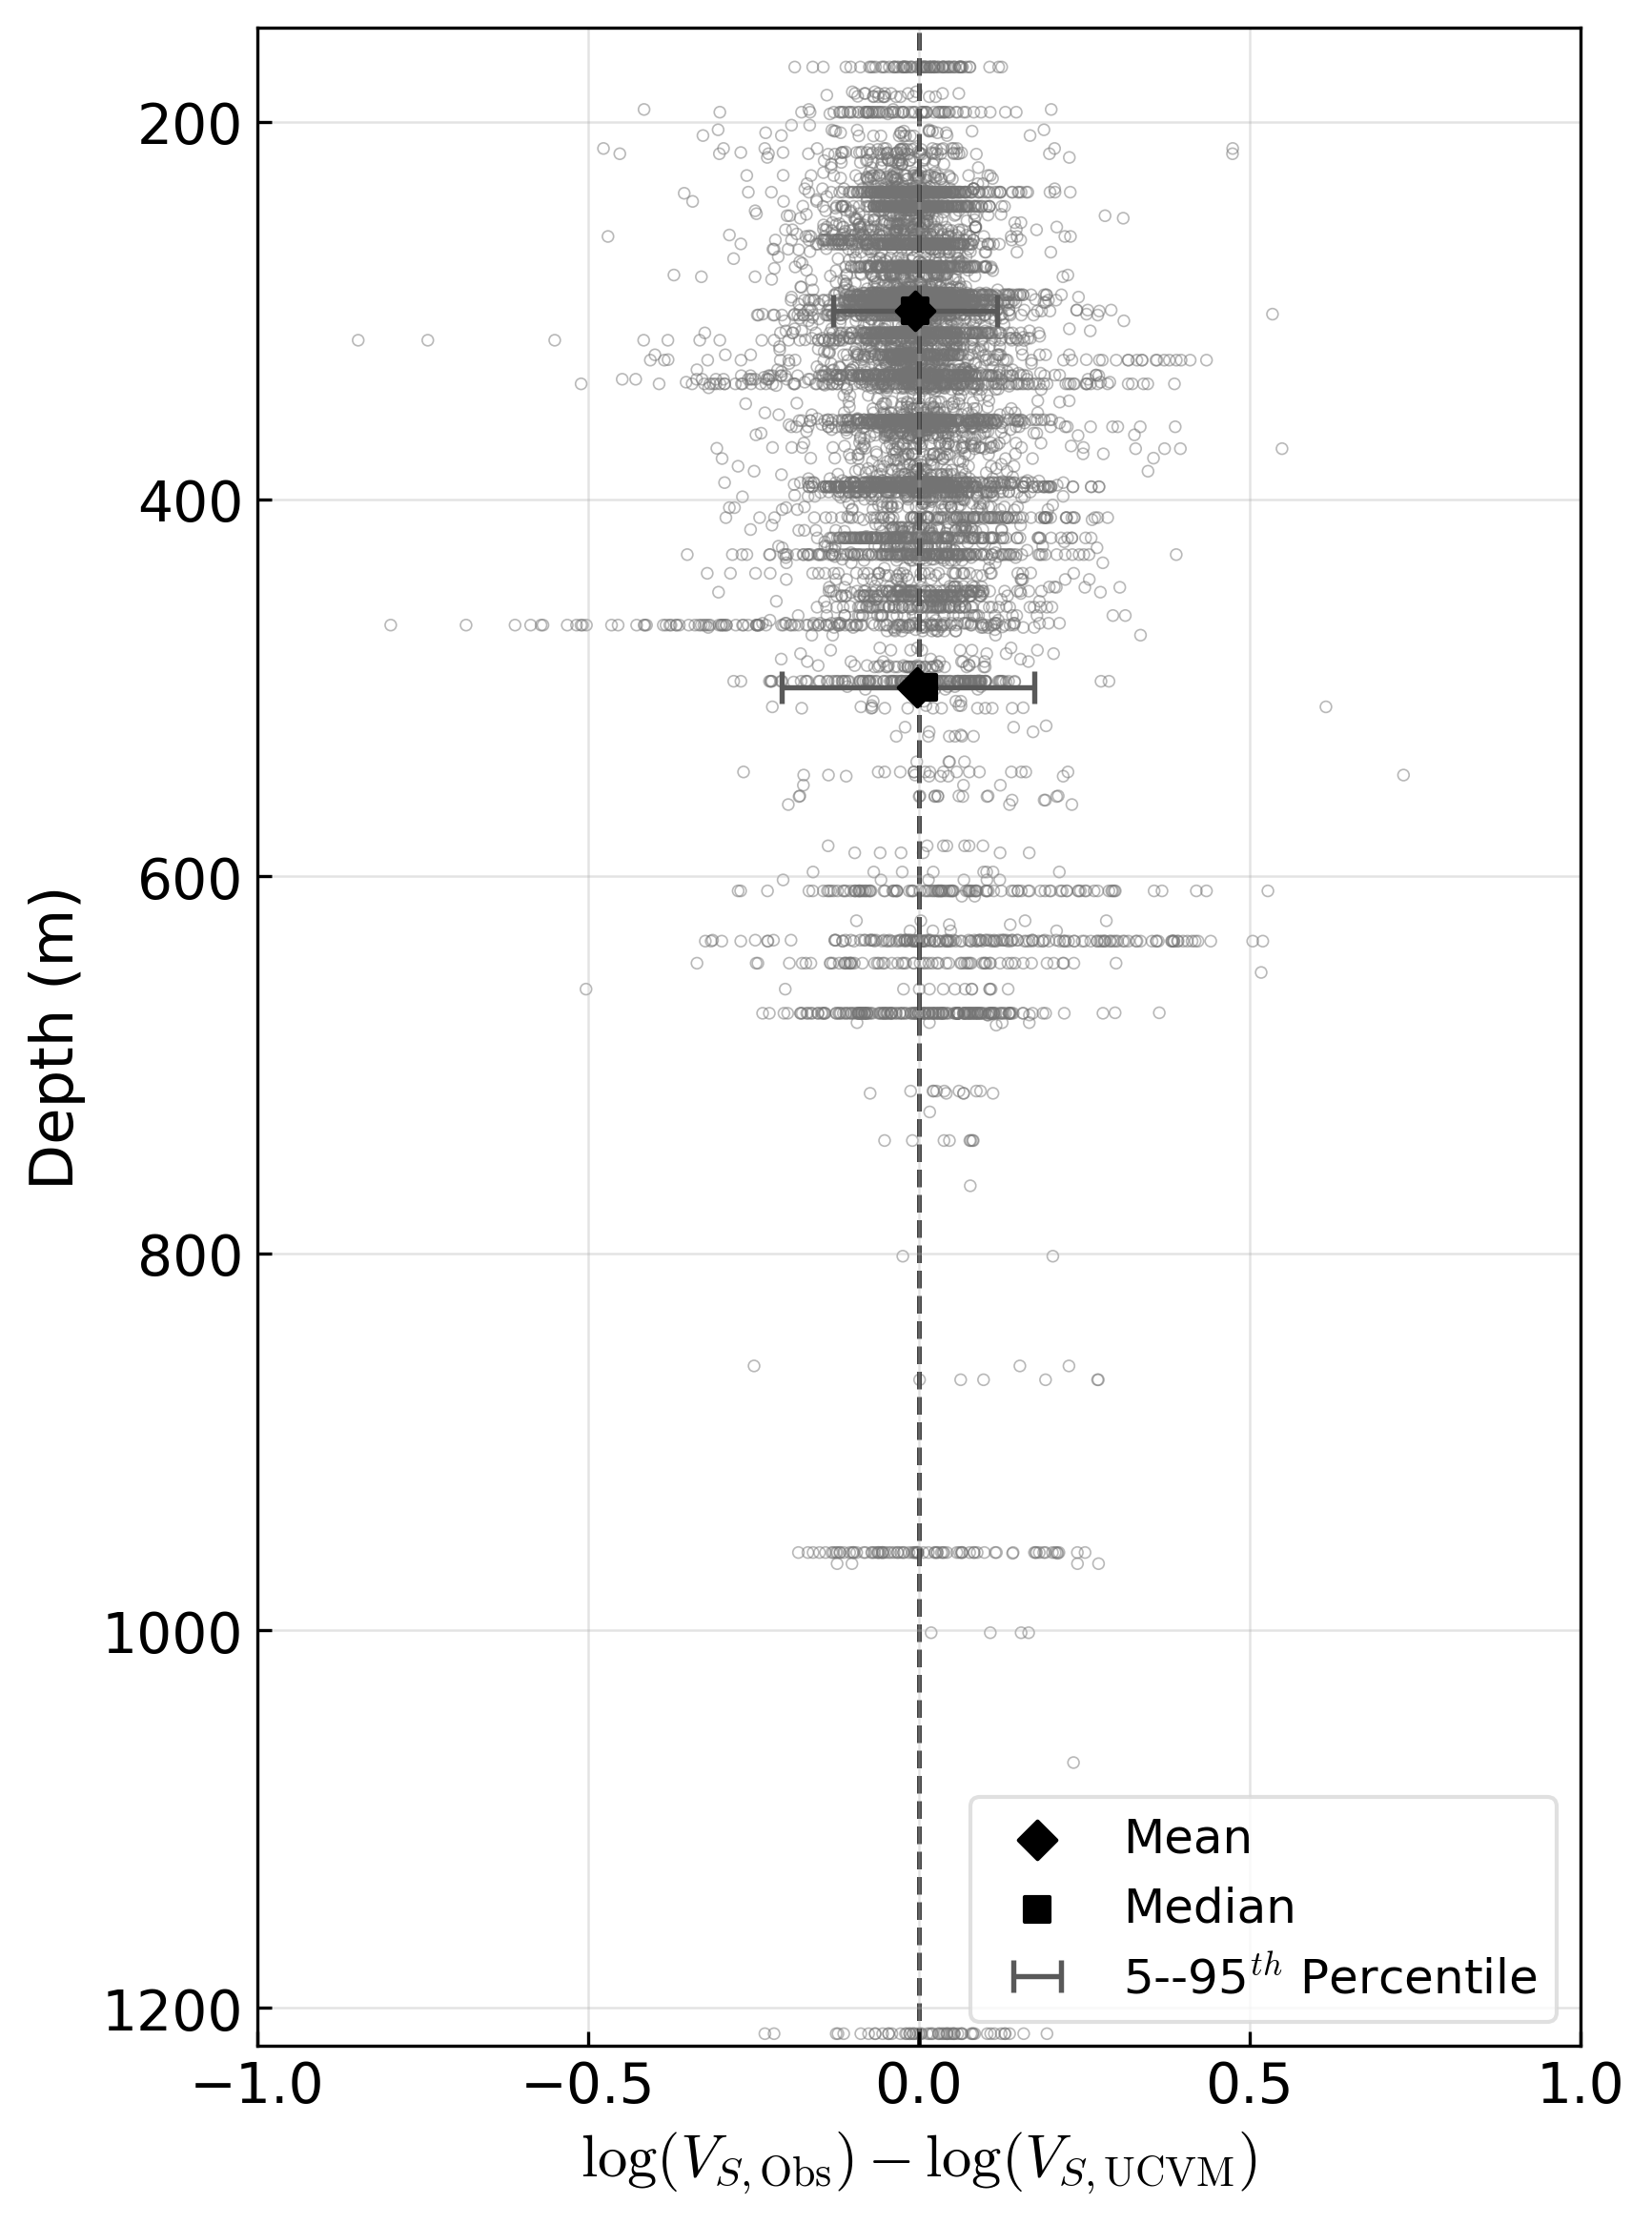

In [16]:
x = df_measure["residual"].to_numpy()
z = df_measure["vs30"].to_numpy()

mask = np.isfinite(x) & np.isfinite(z)
x = x[mask]
z = z[mask]

depth_bins = np.array([200, 400, 600])
depth_centers = 0.5 * (depth_bins[:-1] + depth_bins[1:])

stats = []

for zmin, zmax, zc in zip(depth_bins[:-1], depth_bins[1:], depth_centers):
    idx = (z >= zmin) & (z < zmax)
    x_bin = x[idx]

    if len(x_bin) > 0:
        stats.append([
            zc,
            np.mean(x_bin),
            np.median(x_bin),
            np.percentile(x_bin, 5),
            np.percentile(x_bin, 95),
            len(x_bin)
        ])

stats = pd.DataFrame(
    stats,
    columns=["depth", "mean", "median", "p16", "p84", "n"]
)


plt.rcParams["font.family"] = "Arial"
plt.rcParams["font.size"] = 14

fig, ax = plt.subplots(figsize=(6, 8), dpi=300)

ax.scatter(
    x, z,
    s=8,
    facecolors="none",
    edgecolors="0.45",
    linewidths=0.4,
    alpha=0.5,
    label="_nolegend_"
)

ax.axvline(
    0,
    color="0.25",
    linestyle="--",
    linewidth=1.2,
    zorder=1
)

ax.scatter(
    stats["mean"],
    stats["depth"],
    marker="D",
    s=45,
    color="black",
    label="Mean",
    zorder=5
)

ax.scatter(
    stats["median"],
    stats["depth"],
    marker="s",
    s=40,
    color="black",
    label="Median",
    zorder=5
)

xerr_lower = stats["median"] - stats["p16"]
xerr_upper = stats["p84"] - stats["median"]

ax.errorbar(
    stats["median"],
    stats["depth"],
    xerr=[xerr_lower, xerr_upper],
    fmt="none",
    ecolor="0.35",
    elinewidth=1.3,
    capsize=4,
    capthick=1.3,
    label=r"5--95$^{th}$ Percentile",
    zorder=4
)

ax.invert_yaxis()
ax.set_xlabel(r"$\log(V_{S,\mathrm{Obs}}) - \log(V_{S,\mathrm{UCVM}})$", fontsize=15)
ax.set_ylabel("Depth (m)", fontsize=15)
ax.set_xlim(-1, 1)
ax.set_ylim(1220, 150)

ax.grid(
    True,
    linestyle="-",
    linewidth=0.6,
    alpha=0.35
)

ax.legend(
    loc="lower right",
    fontsize=12,
    frameon=True,
    edgecolor="0.85"
)

plt.tight_layout()
plt.show()